# Klasifikasi Penyakit Buah Jeruk dengan CNN (TensorFlow/Keras)
Tugas 1 Deep Learning. Isi notebook ini: eksplorasi data, preprocessing, pembagian data,
input pipeline `tf.data`, CNN dasar (dari nol, tanpa transfer learning), training,
evaluasi, dan perbaikan model. Semua angka di laporan diambil dari hasil run notebook ini.

Kelas: `blackspot`, `canker`, `fresh`, `grenning`.

In [1]:
import os, json, time, random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support

SEED = 42
random.seed(SEED); np.random.seed(SEED)
keras.utils.set_random_seed(SEED)

IMG_SIZE   = 128
BATCH_SIZE = 32
EPOCHS     = int(os.environ.get("EPOCHS", 60))   # batas atas, biasanya berhenti duluan karena early stopping
LIMIT      = int(os.environ.get("LIMIT", 0))     # buat tes cepat saja (0 = pakai semua data)
AUTOTUNE   = tf.data.AUTOTUNE

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [2]:
# versi lingkungan yang dipakai (salin ke tabel library di laporan)
import sys, platform, importlib.metadata as md
print("Python    :", sys.version.split()[0], "|", platform.system(), platform.release())
print("Perangkat :", [d.device_type for d in tf.config.list_physical_devices()])
for paket in ["tensorflow", "keras", "numpy", "scikit-learn", "matplotlib", "pillow", "opencv-python", "flask"]:
    try:
        print(f"{paket:14s}:", md.version(paket))
    except md.PackageNotFoundError:
        print(f"{paket:14s}: tidak terpasang")

Python    : 3.11.5 | Windows 10
Perangkat : ['CPU']
tensorflow    : 2.21.0
keras         : 3.15.1
numpy         : 2.4.6
scikit-learn  : 1.9.1
matplotlib    : 3.11.2
pillow        : 13.0.0
opencv-python : 5.0.0.93
flask         : 3.1.3


## 1. Setup path dan eksplorasi data

In [3]:
# cari folder dataset, otomatis nyesuaiin kalau notebook dijalankan dari subfolder
DATA_DIR = None
for kandidat in ["dataset/train", "../dataset/train"]:
    if os.path.isdir(kandidat):
        DATA_DIR = kandidat
        break
assert DATA_DIR is not None, "Folder dataset/train tidak ditemukan"

ROOT    = os.path.normpath(os.path.join(DATA_DIR, "..", ".."))   # folder project (tempat app.py)
OUT_DIR = os.path.join(ROOT, "laporan")
os.makedirs(OUT_DIR, exist_ok=True)

categories = sorted(d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d)))
print("Kelas (urutan = indeks output model):", categories)

Kelas (urutan = indeks output model): ['blackspot', 'canker', 'fresh', 'grenning']


blackspot : 184 gambar
canker    : 179 gambar
fresh     : 281 gambar
grenning  : 347 gambar
Total: 991


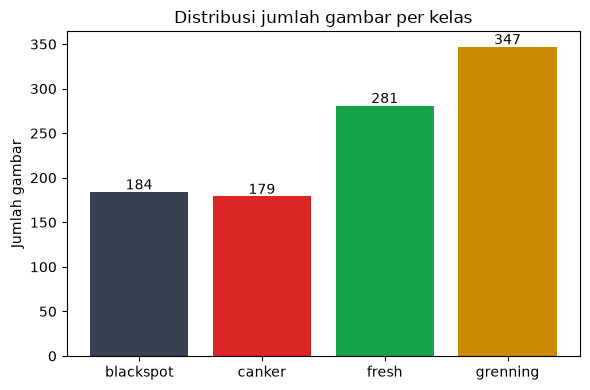

In [4]:
# jumlah gambar per kelas
EXT = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
jumlah = {}
for cat in categories:
    files = [f for f in os.listdir(os.path.join(DATA_DIR, cat)) if f.lower().endswith(EXT)]
    jumlah[cat] = len(files)
    print(f"{cat:10s}: {len(files)} gambar")
print("Total:", sum(jumlah.values()))

plt.figure(figsize=(6, 4))
bars = plt.bar(jumlah.keys(), jumlah.values(), color=["#374151", "#DC2626", "#16A34A", "#CA8A04"])
for b, v in zip(bars, jumlah.values()):
    plt.text(b.get_x() + b.get_width()/2, v + 3, str(v), ha="center")
plt.title("Distribusi jumlah gambar per kelas")
plt.ylabel("Jumlah gambar")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "distribusi_kelas.png"), dpi=150)
plt.show()

In [5]:
# cek file gambar yang rusak/tidak valid + lihat mode warna dan ukuran
paths, labels = [], []
rusak, mode_count, ukuran = [], {}, set()
for idx, cat in enumerate(categories):
    folder = os.path.join(DATA_DIR, cat)
    for f in sorted(os.listdir(folder)):
        if not f.lower().endswith(EXT):
            continue
        p = os.path.join(folder, f)
        try:
            with Image.open(p) as im:
                im.verify()
            with Image.open(p) as im:
                mode_count[im.mode] = mode_count.get(im.mode, 0) + 1
                ukuran.add(im.size)
            paths.append(p)
            labels.append(idx)
        except Exception as e:
            rusak.append((p, str(e)))

print("Gambar valid     :", len(paths))
print("Gambar tidak valid:", len(rusak))
print("Mode warna asli  :", mode_count, "(semua dikonversi ke RGB 3 channel di pipeline)")
print("Jumlah variasi ukuran asli:", len(ukuran), "-> di-resize ke", (IMG_SIZE, IMG_SIZE))

paths  = np.array(paths)
labels = np.array(labels, dtype=np.int32)
if LIMIT:
    sel = np.random.RandomState(SEED).permutation(len(paths))[:LIMIT]
    paths, labels = paths[sel], labels[sel]

Gambar valid     : 991
Gambar tidak valid: 0
Mode warna asli  : {'RGB': 959, 'RGBA': 32} (semua dikonversi ke RGB 3 channel di pipeline)
Jumlah variasi ukuran asli: 144 -> di-resize ke (128, 128)


In [6]:
# cek duplikat: file dengan isi yang sama persis (hash MD5) dihitung duplikat
import hashlib
hash_ke_path = {}
for p in paths:
    with open(p, "rb") as f:
        h = hashlib.md5(f.read()).hexdigest()
    hash_ke_path.setdefault(h, []).append(p)
duplikat = {h: ps for h, ps in hash_ke_path.items() if len(ps) > 1}
print("Jumlah file           :", len(paths))
print("Jumlah isi file unik  :", len(hash_ke_path))
print("Kelompok file duplikat:", len(duplikat))

Jumlah file           : 991
Jumlah isi file unik  : 991
Kelompok file duplikat: 0


In [7]:
# karakteristik berkas per kelas: format, mode warna, dan ukuran asli
from collections import Counter
for idx_kelas, cat in enumerate(categories):
    fmt, mode, lebar, tinggi = Counter(), Counter(), [], []
    for p in paths[labels == idx_kelas]:
        fmt[os.path.splitext(p)[1].lower()] += 1
        with Image.open(p) as im:
            mode[im.mode] += 1
            lebar.append(im.size[0]); tinggi.append(im.size[1])
    print(f"{cat:10s} | format {dict(fmt)} | mode {dict(mode)} | lebar {min(lebar)}-{max(lebar)} | "
          f"tinggi {min(tinggi)}-{max(tinggi)} | ukuran berbeda: {len(set(zip(lebar, tinggi)))}")

blackspot  | format {'.jpg': 184} | mode {'RGB': 184} | lebar 800-800 | tinggi 800-800 | ukuran berbeda: 1
canker     | format {'.jpg': 179} | mode {'RGB': 179} | lebar 800-800 | tinggi 800-800 | ukuran berbeda: 1
fresh      | format {'.png': 281} | mode {'RGB': 249, 'RGBA': 32} | lebar 144-584 | tinggi 138-476 | ukuran berbeda: 143
grenning   | format {'.jpg': 347} | mode {'RGB': 347} | lebar 800-800 | tinggi 800-800 | ukuran berbeda: 1


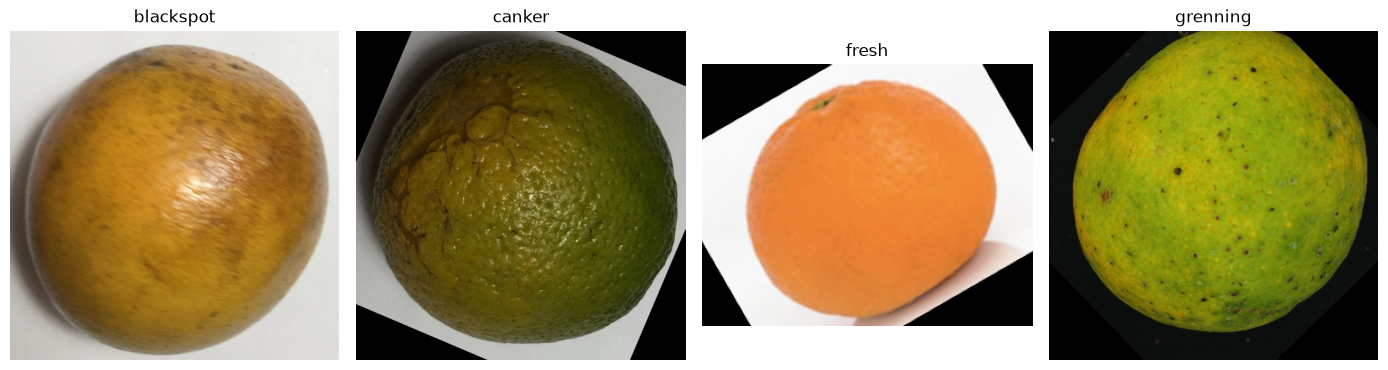

In [8]:
# contoh gambar tiap kelas
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for i, cat in enumerate(categories):
    p = paths[labels == i][0]
    axes[i].imshow(Image.open(p).convert("RGB"))
    axes[i].set_title(cat); axes[i].axis("off")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "contoh_gambar_kelas.png"), dpi=150)
plt.show()

## 2. Pembagian data (stratified): 64% train, 16% validation, 20% test
Pembagian dilakukan di level path file sebelum pipeline dibuat, jadi gambar yang sama
tidak mungkin masuk ke dua subset.

In [9]:
p_trval, p_test, y_trval, y_test = train_test_split(
    paths, labels, test_size=0.20, random_state=SEED, stratify=labels)
p_train, p_val, y_train, y_val = train_test_split(
    p_trval, y_trval, test_size=0.20, random_state=SEED, stratify=y_trval)   # 0.8 x 0.2 = 16%

print(f"Train: {len(p_train)} | Val: {len(p_val)} | Test: {len(p_test)}")
for nama, y in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{nama:5s}:", {categories[k]: int((y == k).sum()) for k in range(len(categories))})

Train: 633 | Val: 159 | Test: 199
train: {'blackspot': 118, 'canker': 114, 'fresh': 180, 'grenning': 221}
val  : {'blackspot': 29, 'canker': 29, 'fresh': 45, 'grenning': 56}
test : {'blackspot': 37, 'canker': 36, 'fresh': 56, 'grenning': 70}


## 3. Input pipeline `tf.data`
- `map()` membaca file, decode ke RGB, resize 128x128, normalisasi ke [0, 1]
- `cache()` supaya decode dan resize tidak diulang tiap epoch
- `shuffle()` hanya untuk training
- `batch()` dan `prefetch()`
- augmentasi hanya diterapkan di dataset training

In [10]:
def load_image(path, label):
    raw = tf.io.read_file(path)
    img = tf.io.decode_image(raw, channels=3, expand_animations=False)   # paksa RGB 3 channel
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))                      # float32, skala 0-255
    img.set_shape((IMG_SIZE, IMG_SIZE, 3))
    return img, label

def normalize(img, label):
    return img / 255.0, label

# augmentasi (dipakai hanya di data training)
augmenter = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.15, value_range=(0, 1)),
    layers.RandomBrightness(0.1, value_range=(0, 1)),
], name="augmentasi")

def make_dataset(p, y, training=False, augment=False):
    ds = tf.data.Dataset.from_tensor_slices((p, y))
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    ds = ds.map(normalize, num_parallel_calls=AUTOTUNE)
    ds = ds.cache()
    if training:
        ds = ds.shuffle(len(p), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH_SIZE)
    if training and augment:
        ds = ds.map(lambda x, t: (augmenter(x, training=True), t), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

val_ds  = make_dataset(p_val,  y_val)
test_ds = make_dataset(p_test, y_test)

xb, yb = next(iter(make_dataset(p_train, y_train, training=True, augment=True)))
print("Bentuk batch:", xb.shape, yb.shape, "| min/max piksel:", float(tf.reduce_min(xb)), float(tf.reduce_max(xb)))

Bentuk batch: (32, 128, 128, 3) (32,) | min/max piksel: 0.0 1.0


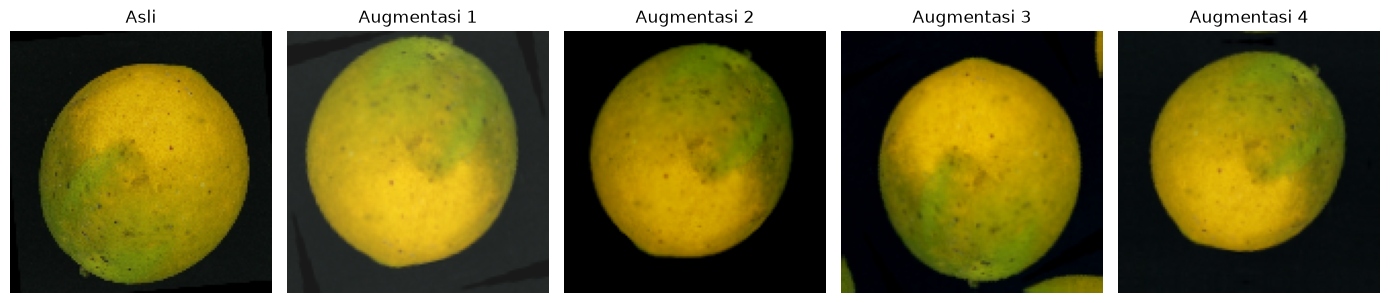

In [11]:
# contoh hasil augmentasi pada satu gambar training
contoh, _ = load_image(p_train[0], y_train[0])
contoh = (contoh / 255.0)[None]
fig, axes = plt.subplots(1, 5, figsize=(14, 3))
axes[0].imshow(contoh[0]); axes[0].set_title("Asli")
for i in range(1, 5):
    axes[i].imshow(np.clip(augmenter(contoh, training=True)[0], 0, 1)); axes[i].set_title(f"Augmentasi {i}")
for a in axes: a.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "contoh_augmentasi.png"), dpi=150)
plt.show()

## 4. Arsitektur CNN dasar (dilatih dari awal)
Tiga blok Conv2D, Batch Normalization, ReLU, MaxPooling2D, lalu GlobalAveragePooling2D,
Dense, Dropout, dan Softmax 4 kelas. Tidak memakai transfer learning maupun model pretrained.

In [12]:
def build_model(dropout=0.5, bn_momentum=0.99):
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = inputs
    for f in (32, 64, 128):
        x = layers.Conv2D(f, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization(momentum=bn_momentum)(x)
        x = layers.ReLU()(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(len(categories), activation="softmax")(x)
    return keras.Model(inputs, outputs, name="cnn_jeruk")

build_model().summary()
with open(os.path.join(OUT_DIR, "arsitektur_model.txt"), "w", encoding="utf-8") as f:
    build_model().summary(print_fn=lambda s: f.write(s + "\n"))

Model: "cnn_jeruk"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,948 (433.39 KB)

 Trainable params: 110,500 (431.64 KB)

 Non-trainable params: 448 (1.75 KB)

## 5. Training, evaluasi, dan perbaikan model
Komponen yang dipakai di semua eksperimen:
- Loss: sparse categorical crossentropy (label integer, output softmax)
- Optimizer: Adam
- Dropout 0.5 dan Batch Normalization di dalam model
- Learning-rate scheduling: `ReduceLROnPlateau` (monitor val_loss, faktor 0.5, patience 4)
- Early stopping: monitor val_loss, patience 10, `restore_best_weights=True`

Pemilihan model akhir memakai akurasi validasi. Data test hanya dipakai untuk melaporkan hasil.

In [13]:
def plot_history(h, nama):
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(h["loss"], label="train"); ax[0].plot(h["val_loss"], label="val")
    ax[0].set_title(f"Loss - {nama}"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(h["accuracy"], label="train"); ax[1].plot(h["val_accuracy"], label="val")
    ax[1].set_title(f"Akurasi - {nama}"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, f"kurva_{nama}.png"), dpi=150)
    plt.show()

def plot_cm(cm, nama):
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(categories))); ax.set_yticks(range(len(categories)))
    ax.set_xticklabels(categories, rotation=45); ax.set_yticklabels(categories)
    ax.set_xlabel("Prediksi"); ax.set_ylabel("Label asli"); ax.set_title(f"Confusion matrix - {nama}")
    for i in range(len(categories)):
        for j in range(len(categories)):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max()/2 else "black")
    plt.colorbar(im); plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, f"confusion_matrix_{nama}.png"), dpi=150)
    plt.show()

def run_experiment(nama, augment, lr=1e-3, dropout=0.5, bn_momentum=0.99, deskripsi=""):
    print(f"\n===== {nama}: {deskripsi} =====")
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)
    train_ds = make_dataset(p_train, y_train, training=True, augment=augment)

    model = build_model(dropout, bn_momentum)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    cb = [
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5, verbose=1),
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True, verbose=1),
    ]
    t0 = time.time()
    hist = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=cb, verbose=2)
    waktu = time.time() - t0
    h = hist.history
    plot_history(h, nama)

    # evaluasi di data validation dan test (dataset tidak di-shuffle, jadi urutan sama dengan y_val / y_test)
    val_loss, val_acc = model.evaluate(val_ds, verbose=0)
    y_pred = np.argmax(model.predict(test_ds, verbose=0), axis=1)
    test_acc = float(np.mean(y_pred == y_test))
    prec, rec, f1, _ = precision_recall_fscore_support(y_test, y_pred, average="macro", zero_division=0)
    print(f"\nVal acc: {val_acc*100:.2f}% | Test acc: {test_acc*100:.2f}% | "
          f"Precision (macro): {prec*100:.2f}% | Recall (macro): {rec*100:.2f}%")
    print(classification_report(y_test, y_pred, target_names=categories, digits=4, zero_division=0))
    cm = confusion_matrix(y_test, y_pred)
    print("Confusion matrix:\n", cm)
    plot_cm(cm, nama)

    hasil = dict(
        nama=nama, deskripsi=deskripsi, augmentasi=augment, lr_awal=lr, dropout=dropout, bn_momentum=bn_momentum,
        epoch_jalan=len(h["loss"]), epoch_terbaik=int(np.argmin(h["val_loss"])) + 1,
        lr_akhir=float(h["learning_rate"][-1]) if "learning_rate" in h else None,
        train_acc_akhir=float(h["accuracy"][-1]), val_acc=float(val_acc), val_loss=float(val_loss),
        test_acc=test_acc, precision_macro=float(prec), recall_macro=float(rec), f1_macro=float(f1),
        report=classification_report(y_test, y_pred, target_names=categories, output_dict=True, zero_division=0),
        confusion_matrix=cm.tolist(), waktu_detik=round(waktu, 1), jumlah_parameter=int(model.count_params()),
    )
    return model, hasil

### Eksperimen 1: baseline
Konfigurasi default Keras (Batch Normalization `momentum=0.99`), tanpa augmentasi.


===== exp1_baseline: CNN dasar, Adam lr 1e-3, BN momentum 0.99 (default Keras), tanpa augmentasi =====

Epoch 1/60


c:\Users\LENOVO\Downloads\Proyek_Jeruk_Kelompok1\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


20/20 - 16s - 795ms/step - accuracy: 0.7188 - loss: 0.6831 - val_accuracy: 0.3019 - val_loss: 1.2267 - learning_rate: 0.0010
Epoch 2/60
20/20 - 14s - 694ms/step - accuracy: 0.8452 - loss: 0.3591 - val_accuracy: 0.3270 - val_loss: 1.3072 - learning_rate: 0.0010
Epoch 3/60
20/20 - 15s - 764ms/step - accuracy: 0.8689 - loss: 0.2855 - val_accuracy: 0.3522 - val_loss: 1.4296 - learning_rate: 0.0010
Epoch 4/60
20/20 - 14s - 705ms/step - accuracy: 0.9052 - loss: 0.2305 - val_accuracy: 0.2013 - val_loss: 1.7307 - learning_rate: 0.0010
Epoch 5/60

Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
20/20 - 12s - 610ms/step - accuracy: 0.8926 - loss: 0.2274 - val_accuracy: 0.2767 - val_loss: 2.0006 - learning_rate: 0.0010
Epoch 6/60
20/20 - 13s - 670ms/step - accuracy: 0.9021 - loss: 0.2162 - val_accuracy: 0.1950 - val_loss: 2.2618 - learning_rate: 5.0000e-04
Epoch 7/60
20/20 - 13s - 673ms/step - accuracy: 0.9210 - loss: 0.1986 - val_accuracy: 0.3270 - val_loss: 2.2549 - 

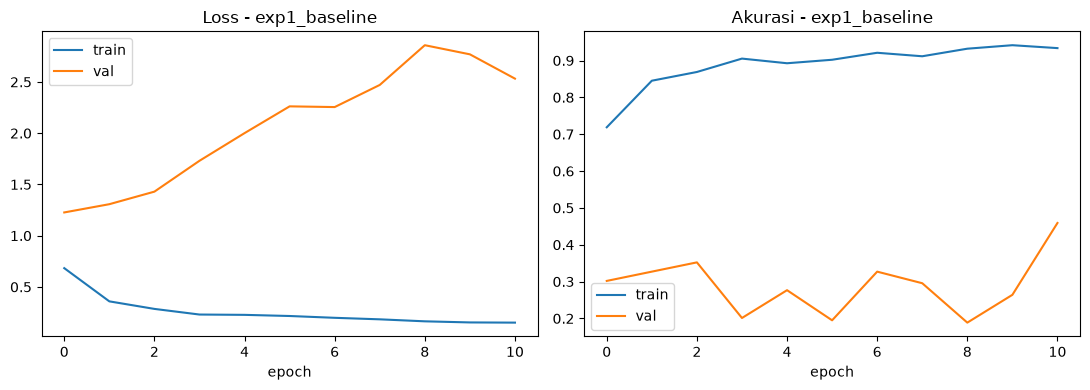


Val acc: 30.19% | Test acc: 30.65% | Precision (macro): 13.57% | Recall (macro): 28.38%
              precision    recall  f1-score   support

   blackspot     0.0602    0.1351    0.0833        37
      canker     0.0000    0.0000    0.0000        36
       fresh     0.4828    1.0000    0.6512        56
    grenning     0.0000    0.0000    0.0000        70

    accuracy                         0.3065       199
   macro avg     0.1357    0.2838    0.1836       199
weighted avg     0.1471    0.3065    0.1987       199

Confusion matrix:
 [[ 5  0 32  0]
 [ 8  0 28  0]
 [ 0  0 56  0]
 [70  0  0  0]]


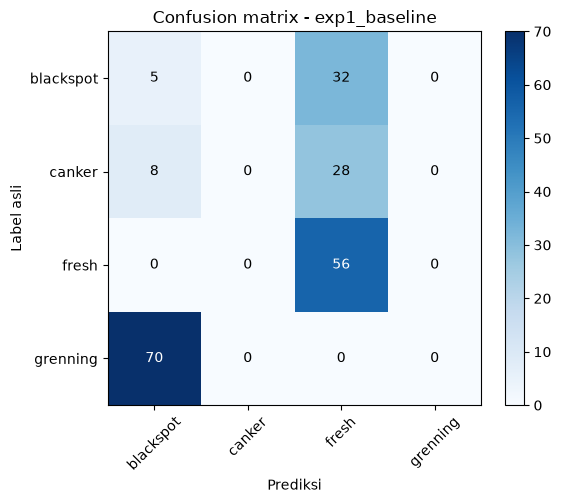

In [14]:
model_1, hasil_1 = run_experiment("exp1_baseline", augment=False,
                                  deskripsi="CNN dasar, Adam lr 1e-3, BN momentum 0.99 (default Keras), tanpa augmentasi")

Catatan dari eksperimen 1: akurasi training tinggi tetapi akurasi validation rendah dan tidak stabil
sejak epoch pertama. Dugaannya bukan overfitting biasa, melainkan statistik Batch Normalization
(moving average dengan momentum 0.99) belum sempat konvergen karena satu epoch hanya berisi sekitar 20 langkah.
Dugaan ini dicek dengan mengevaluasi model pada data training dalam mode inferensi (`training=False`).

In [15]:
# cek dugaan: kalau BN-nya belum konvergen, akurasi di data train pun akan jelek saat mode inferensi
cek_bn_hasil = {}
def cek_bn(bn_momentum, epochs=8):
    keras.backend.clear_session(); keras.utils.set_random_seed(SEED)
    m = build_model(0.5, bn_momentum)
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    m.fit(make_dataset(p_train, y_train, training=True), epochs=epochs, verbose=0)
    acc_train = m.evaluate(make_dataset(p_train, y_train), verbose=0)[1]
    acc_val   = m.evaluate(val_ds, verbose=0)[1]
    cek_bn_hasil[str(bn_momentum)] = {"train_mode_inferensi": float(acc_train), "val": float(acc_val)}
    print(f"BN momentum {bn_momentum}: akurasi train (mode inferensi) {acc_train*100:.1f}% | val {acc_val*100:.1f}%")

cek_bn(0.99)
cek_bn(0.9)

c:\Users\LENOVO\Downloads\Proyek_Jeruk_Kelompok1\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


BN momentum 0.99: akurasi train (mode inferensi) 42.8% | val 44.0%
BN momentum 0.9: akurasi train (mode inferensi) 95.6% | val 96.2%


### Eksperimen 2: perbaikan Batch Normalization (`momentum=0.9`)
Momentum 0.9 membuat moving average BN menyesuaikan lebih cepat, cocok untuk dataset kecil
dengan jumlah langkah per epoch yang sedikit.


===== exp2_bn_momentum: BN momentum 0.9, tanpa augmentasi =====
Epoch 1/60
20/20 - 16s - 793ms/step - accuracy: 0.7188 - loss: 0.6831 - val_accuracy: 0.1824 - val_loss: 1.2995 - learning_rate: 0.0010
Epoch 2/60
20/20 - 13s - 656ms/step - accuracy: 0.8452 - loss: 0.3591 - val_accuracy: 0.7925 - val_loss: 0.5606 - learning_rate: 0.0010
Epoch 3/60
20/20 - 12s - 577ms/step - accuracy: 0.8689 - loss: 0.2855 - val_accuracy: 0.9497 - val_loss: 0.1921 - learning_rate: 0.0010
Epoch 4/60
20/20 - 12s - 603ms/step - accuracy: 0.9052 - loss: 0.2305 - val_accuracy: 0.9308 - val_loss: 0.1610 - learning_rate: 0.0010
Epoch 5/60
20/20 - 12s - 593ms/step - accuracy: 0.8926 - loss: 0.2274 - val_accuracy: 0.9434 - val_loss: 0.1291 - learning_rate: 0.0010
Epoch 6/60
20/20 - 12s - 595ms/step - accuracy: 0.8926 - loss: 0.2219 - val_accuracy: 0.8176 - val_loss: 0.3084 - learning_rate: 0.0010
Epoch 7/60
20/20 - 11s - 569ms/step - accuracy: 0.9068 - loss: 0.1978 - val_accuracy: 0.9497 - val_loss: 0.1133 - learn

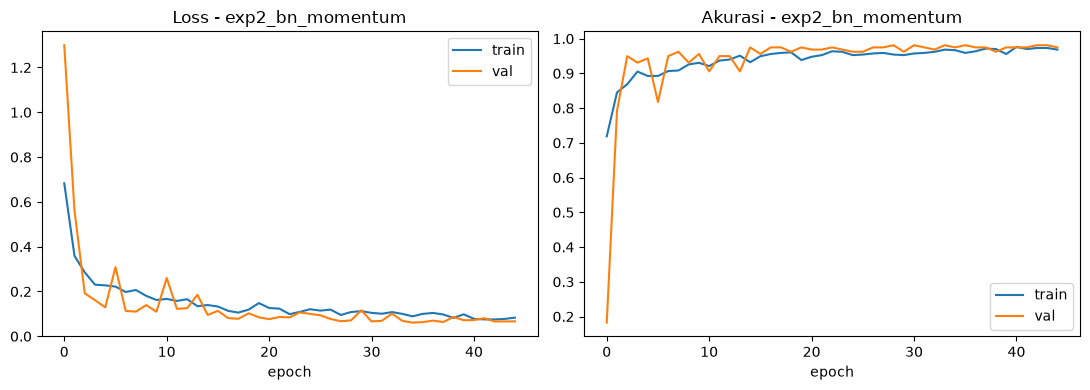


Val acc: 97.48% | Test acc: 96.98% | Precision (macro): 95.94% | Recall (macro): 95.91%
              precision    recall  f1-score   support

   blackspot     0.9429    0.8919    0.9167        37
      canker     0.8947    0.9444    0.9189        36
       fresh     1.0000    1.0000    1.0000        56
    grenning     1.0000    1.0000    1.0000        70

    accuracy                         0.9698       199
   macro avg     0.9594    0.9591    0.9589       199
weighted avg     0.9703    0.9698    0.9698       199

Confusion matrix:
 [[33  4  0  0]
 [ 2 34  0  0]
 [ 0  0 56  0]
 [ 0  0  0 70]]


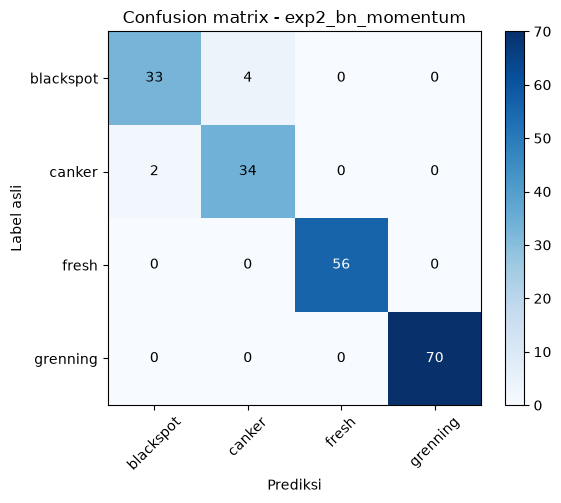

In [16]:
model_2, hasil_2 = run_experiment("exp2_bn_momentum", augment=False, bn_momentum=0.9,
                                  deskripsi="BN momentum 0.9, tanpa augmentasi")

### Eksperimen 3: tambah augmentasi pada data training
Augmentasi (flip, rotasi, zoom, kontras, brightness) hanya diterapkan di dataset training.
Tujuannya melihat apakah augmentasi menambah performa pada data validation dan test.


===== exp3_augmentasi: BN momentum 0.9 + augmentasi data training =====
Epoch 1/60


c:\Users\LENOVO\Downloads\Proyek_Jeruk_Kelompok1\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


20/20 - 16s - 791ms/step - accuracy: 0.7093 - loss: 0.6987 - val_accuracy: 0.1824 - val_loss: 1.4839 - learning_rate: 0.0010
Epoch 2/60
20/20 - 12s - 597ms/step - accuracy: 0.8246 - loss: 0.3712 - val_accuracy: 0.6352 - val_loss: 0.8129 - learning_rate: 0.0010
Epoch 3/60
20/20 - 12s - 594ms/step - accuracy: 0.8547 - loss: 0.3227 - val_accuracy: 0.9308 - val_loss: 0.1888 - learning_rate: 0.0010
Epoch 4/60
20/20 - 12s - 579ms/step - accuracy: 0.8768 - loss: 0.2620 - val_accuracy: 0.9434 - val_loss: 0.1500 - learning_rate: 0.0010
Epoch 5/60
20/20 - 12s - 599ms/step - accuracy: 0.8799 - loss: 0.2626 - val_accuracy: 0.8679 - val_loss: 0.2150 - learning_rate: 0.0010
Epoch 6/60
20/20 - 12s - 594ms/step - accuracy: 0.8847 - loss: 0.2603 - val_accuracy: 0.9371 - val_loss: 0.1549 - learning_rate: 0.0010
Epoch 7/60
20/20 - 13s - 643ms/step - accuracy: 0.8863 - loss: 0.2288 - val_accuracy: 0.8931 - val_loss: 0.1964 - learning_rate: 0.0010
Epoch 8/60

Epoch 8: ReduceLROnPlateau reducing learning ra

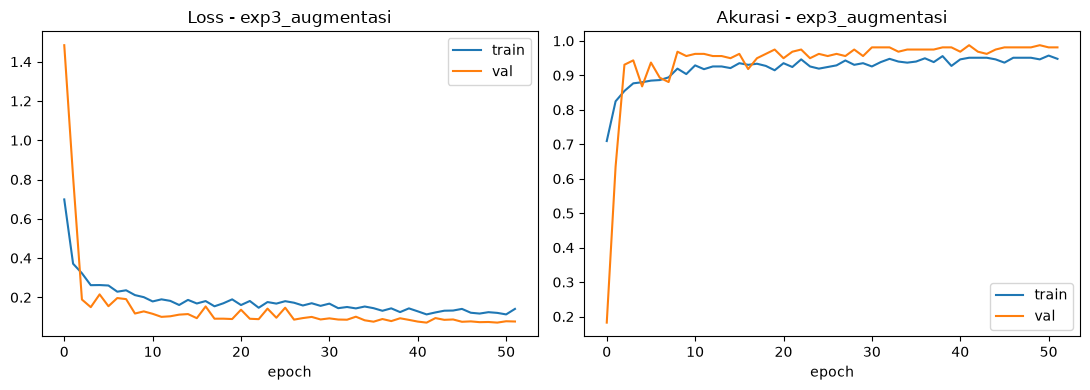


Val acc: 98.74% | Test acc: 94.97% | Precision (macro): 93.63% | Recall (macro): 93.21%
              precision    recall  f1-score   support

   blackspot     0.9355    0.7838    0.8529        37
      canker     0.8095    0.9444    0.8718        36
       fresh     1.0000    1.0000    1.0000        56
    grenning     1.0000    1.0000    1.0000        70

    accuracy                         0.9497       199
   macro avg     0.9363    0.9321    0.9312       199
weighted avg     0.9535    0.9497    0.9495       199

Confusion matrix:
 [[29  8  0  0]
 [ 2 34  0  0]
 [ 0  0 56  0]
 [ 0  0  0 70]]


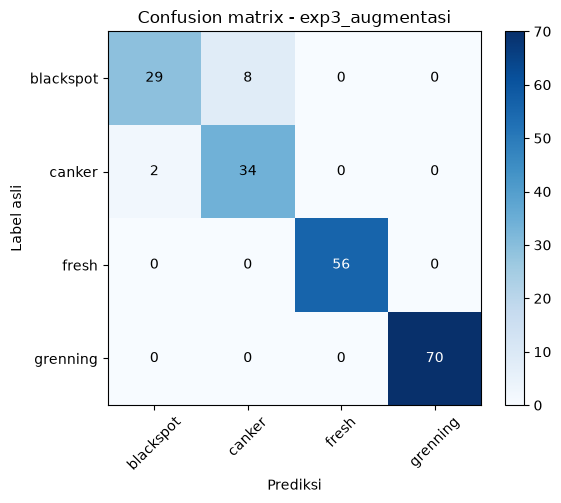

In [17]:
model_3, hasil_3 = run_experiment("exp3_augmentasi", augment=True, bn_momentum=0.9,
                                  deskripsi="BN momentum 0.9 + augmentasi data training")

### Eksperimen 4: pengaruh learning rate awal
Acuan: eksperimen 2 (BN momentum 0.9, tanpa augmentasi). Hanya learning rate awal yang diubah, 1e-3 menjadi 3e-4.


===== exp4_lr_3e-4: Acuan exp2, learning rate awal 3e-4 =====
Epoch 1/60


c:\Users\LENOVO\Downloads\Proyek_Jeruk_Kelompok1\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


20/20 - 15s - 752ms/step - accuracy: 0.6272 - loss: 0.9246 - val_accuracy: 0.1824 - val_loss: 1.4394 - learning_rate: 3.0000e-04
Epoch 2/60
20/20 - 12s - 608ms/step - accuracy: 0.8278 - loss: 0.4863 - val_accuracy: 0.7296 - val_loss: 0.7796 - learning_rate: 3.0000e-04
Epoch 3/60
20/20 - 12s - 592ms/step - accuracy: 0.8499 - loss: 0.3746 - val_accuracy: 0.8994 - val_loss: 0.2757 - learning_rate: 3.0000e-04
Epoch 4/60
20/20 - 12s - 612ms/step - accuracy: 0.8752 - loss: 0.3045 - val_accuracy: 0.9308 - val_loss: 0.1914 - learning_rate: 3.0000e-04
Epoch 5/60
20/20 - 11s - 566ms/step - accuracy: 0.8752 - loss: 0.2716 - val_accuracy: 0.9245 - val_loss: 0.1681 - learning_rate: 3.0000e-04
Epoch 6/60
20/20 - 11s - 564ms/step - accuracy: 0.8989 - loss: 0.2434 - val_accuracy: 0.9623 - val_loss: 0.1314 - learning_rate: 3.0000e-04
Epoch 7/60
20/20 - 11s - 549ms/step - accuracy: 0.9052 - loss: 0.2426 - val_accuracy: 0.9560 - val_loss: 0.1323 - learning_rate: 3.0000e-04
Epoch 8/60
20/20 - 12s - 615ms/

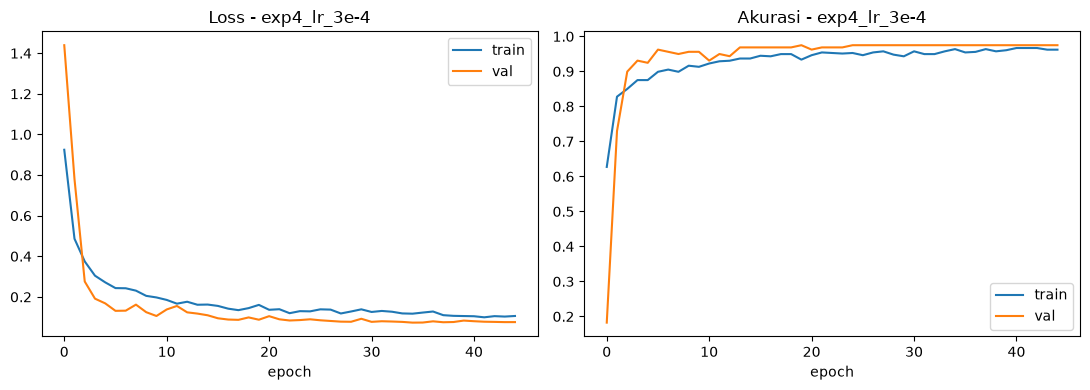


Val acc: 97.48% | Test acc: 95.98% | Precision (macro): 94.78% | Recall (macro): 94.48%
              precision    recall  f1-score   support

   blackspot     0.8537    0.9459    0.8974        37
      canker     0.9375    0.8333    0.8824        36
       fresh     1.0000    1.0000    1.0000        56
    grenning     1.0000    1.0000    1.0000        70

    accuracy                         0.9598       199
   macro avg     0.9478    0.9448    0.9449       199
weighted avg     0.9615    0.9598    0.9596       199

Confusion matrix:
 [[35  2  0  0]
 [ 6 30  0  0]
 [ 0  0 56  0]
 [ 0  0  0 70]]


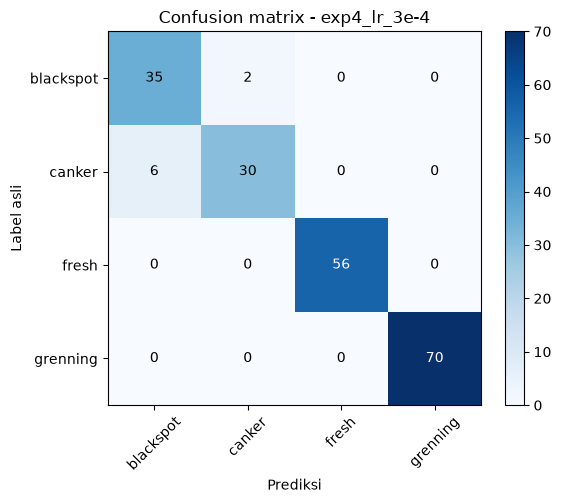

In [18]:
model_4, hasil_4 = run_experiment("exp4_lr_3e-4", augment=False, bn_momentum=0.9, lr=3e-4,
                                  deskripsi="Acuan exp2, learning rate awal 3e-4")

### Eksperimen 5: pengaruh dropout
Acuan: eksperimen 2. Hanya rate dropout yang diubah, 0.5 menjadi 0.3.


===== exp5_dropout_0.3: Acuan exp2, dropout 0.3 =====
Epoch 1/60


c:\Users\LENOVO\Downloads\Proyek_Jeruk_Kelompok1\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


20/20 - 15s - 766ms/step - accuracy: 0.7536 - loss: 0.5980 - val_accuracy: 0.2830 - val_loss: 1.3320 - learning_rate: 0.0010
Epoch 2/60
20/20 - 12s - 588ms/step - accuracy: 0.8641 - loss: 0.3017 - val_accuracy: 0.7233 - val_loss: 0.5907 - learning_rate: 0.0010
Epoch 3/60
20/20 - 12s - 585ms/step - accuracy: 0.8863 - loss: 0.2433 - val_accuracy: 0.9057 - val_loss: 0.1984 - learning_rate: 0.0010
Epoch 4/60
20/20 - 12s - 584ms/step - accuracy: 0.9005 - loss: 0.2106 - val_accuracy: 0.9434 - val_loss: 0.1417 - learning_rate: 0.0010
Epoch 5/60
20/20 - 12s - 600ms/step - accuracy: 0.9021 - loss: 0.2137 - val_accuracy: 0.9434 - val_loss: 0.1358 - learning_rate: 0.0010
Epoch 6/60
20/20 - 12s - 579ms/step - accuracy: 0.9163 - loss: 0.2065 - val_accuracy: 0.9057 - val_loss: 0.1777 - learning_rate: 0.0010
Epoch 7/60
20/20 - 12s - 578ms/step - accuracy: 0.9147 - loss: 0.1912 - val_accuracy: 0.9371 - val_loss: 0.1370 - learning_rate: 0.0010
Epoch 8/60
20/20 - 12s - 580ms/step - accuracy: 0.8989 - lo

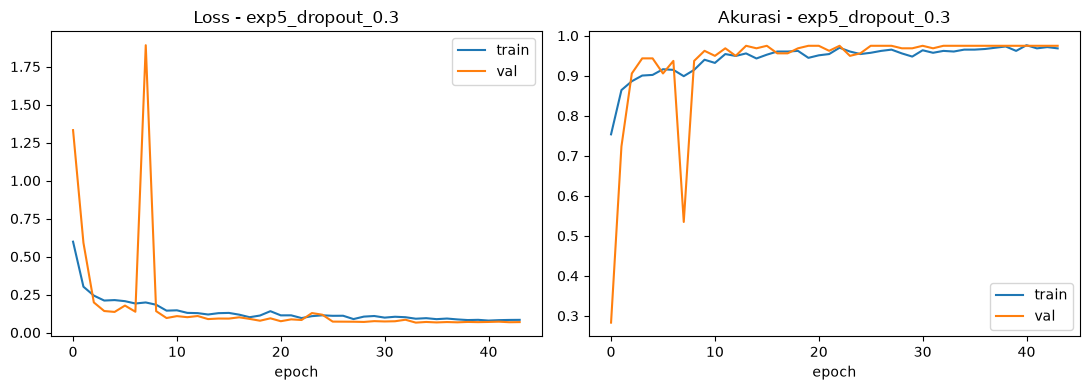


Val acc: 97.48% | Test acc: 97.49% | Precision (macro): 96.58% | Recall (macro): 96.58%
              precision    recall  f1-score   support

   blackspot     0.9444    0.9189    0.9315        37
      canker     0.9189    0.9444    0.9315        36
       fresh     1.0000    1.0000    1.0000        56
    grenning     1.0000    1.0000    1.0000        70

    accuracy                         0.9749       199
   macro avg     0.9658    0.9658    0.9658       199
weighted avg     0.9750    0.9749    0.9749       199

Confusion matrix:
 [[34  3  0  0]
 [ 2 34  0  0]
 [ 0  0 56  0]
 [ 0  0  0 70]]


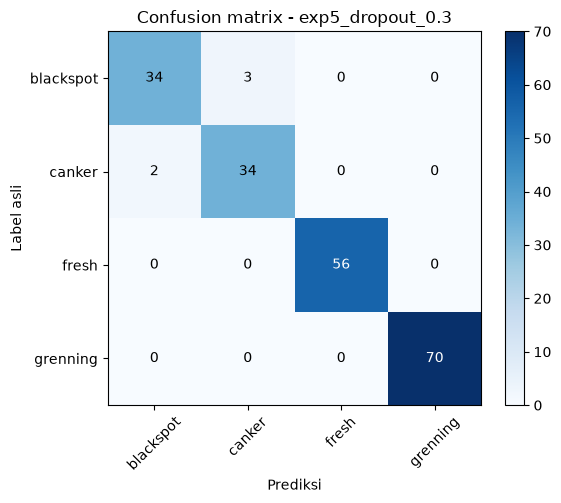

In [19]:
model_5, hasil_5 = run_experiment("exp5_dropout_0.3", augment=False, bn_momentum=0.9, dropout=0.3,
                                  deskripsi="Acuan exp2, dropout 0.3")

## 6. Perbandingan eksperimen dan penyimpanan model

In [20]:
semua = [(model_1, hasil_1), (model_2, hasil_2), (model_3, hasil_3), (model_4, hasil_4), (model_5, hasil_5)]
print(f"{'Eksperimen':18s} {'Epoch':>6s} {'TrainAcc':>9s} {'ValAcc':>8s} {'TestAcc':>8s} {'Prec':>7s} {'Rec':>7s} {'F1':>7s}")
for _, r in semua:
    print(f"{r['nama']:18s} {r['epoch_jalan']:6d} {r['train_acc_akhir']*100:8.2f}% {r['val_acc']*100:7.2f}% "
          f"{r['test_acc']*100:7.2f}% {r['precision_macro']*100:6.2f}% {r['recall_macro']*100:6.2f}% {r['f1_macro']*100:6.2f}%")

# model final dipilih dari akurasi validasi (bukan test), kalau sama pakai val loss terkecil
terbaik_model, terbaik = sorted(semua, key=lambda t: (-t[1]["val_acc"], t[1]["val_loss"]))[0]
print("\nModel final:", terbaik["nama"])

terbaik_model.save(os.path.join(ROOT, "model_cnn.keras"))
with open(os.path.join(ROOT, "class_names.json"), "w", encoding="utf-8") as f:
    json.dump({"class_names": categories, "img_size": IMG_SIZE, "rescale": "1/255", "color_mode": "RGB",
               "model_final": terbaik["nama"]}, f, indent=2)
with open(os.path.join(OUT_DIR, "hasil_eksperimen.json"), "w", encoding="utf-8") as f:
    json.dump({"split": {"train": len(p_train), "val": len(p_val), "test": len(p_test)},
               "jumlah_per_kelas": jumlah, "cek_bn": cek_bn_hasil, "model_final": terbaik["nama"],
               "eksperimen": [r for _, r in semua]}, f, indent=2)
print("Tersimpan: model_cnn.keras, class_names.json, laporan/hasil_eksperimen.json")

Eksperimen          Epoch  TrainAcc   ValAcc  TestAcc    Prec     Rec      F1
exp1_baseline          11    93.36%   30.19%   30.65%  13.57%  28.38%  18.36%
exp2_bn_momentum       45    96.84%   97.48%   96.98%  95.94%  95.91%  95.89%
exp3_augmentasi        52    94.79%   98.74%   94.97%  93.63%  93.21%  93.12%
exp4_lr_3e-4           45    96.21%   97.48%   95.98%  94.78%  94.48%  94.49%
exp5_dropout_0.3       44    96.84%   97.48%   97.49%  96.58%  96.58%  96.58%

Model final: exp3_augmentasi
Tersimpan: model_cnn.keras, class_names.json, laporan/hasil_eksperimen.json


## 7. Fitur unik: Grad-CAM dan confidence threshold
Bagian ini memakai model final yang sudah tersimpan (`model_cnn.keras`), jadi **tidak ada pelatihan ulang**.
Kalau kernel baru dibuka, jalankan dulu sel setup (import, path dataset, pembagian data, dan pipeline `tf.data`
sampai `test_ds`), lalu langsung ke bagian ini.

- **Grad-CAM**: peta panas bagian citra yang paling memengaruhi prediksi, untuk memeriksa apakah model
  melihat buah dan bercaknya atau justru latar belakangnya.
- **Confidence threshold**: prediksi hanya ditampilkan sebagai hasil bila probabilitas tertinggi softmax
  mencapai ambang. Di bawah ambang, aplikasi menampilkan pesan "tidak yakin".

In [21]:
# memuat model final dari berkas, lalu hitung probabilitas pada data validation dan test
# (val_ds dan test_ds tidak di-shuffle, jadi urutannya sama dengan y_val dan y_test)
model_final = keras.models.load_model(os.path.join(ROOT, "model_cnn.keras"))
proba_val   = model_final.predict(val_ds,  verbose=0)
proba_test  = model_final.predict(test_ds, verbose=0)
pred_val, pred_test = proba_val.argmax(1), proba_test.argmax(1)
print("Akurasi validation:", round(float(np.mean(pred_val  == y_val))  * 100, 2), "%")
print("Akurasi test      :", round(float(np.mean(pred_test == y_test)) * 100, 2), "%")

Akurasi validation: 98.74 %
Akurasi test      : 94.97 %


### 7.1 Grad-CAM
Peta fitur yang dipakai adalah keluaran MaxPooling terakhir (16 x 16 x 128), tepat sebelum GlobalAveragePooling.
Bobot tiap peta fitur adalah rata-rata gradien skor kelas terhadap peta tersebut. Skor yang dipakai adalah
skor sebelum softmax supaya gradien tidak jenuh ketika probabilitas mendekati 1.

In [22]:
lapisan_akhir = model_final.layers[-1]                                                        # Dense softmax
lapisan_peta  = [l for l in model_final.layers if isinstance(l, layers.MaxPooling2D)][-1]    # peta fitur terakhir
grad_model    = keras.Model(model_final.inputs, [lapisan_peta.output, model_final.layers[-2].output])

def hitung_gradcam(img, kelas=None):
    """img: array (H, W, 3) skala 0-1. Mengembalikan peta panas 0-1 berukuran H x W dan kelas yang dijelaskan."""
    x = tf.convert_to_tensor(img[None], dtype=tf.float32)
    with tf.GradientTape() as tape:
        peta, h = grad_model(x, training=False)
        skor_semua = tf.matmul(h, lapisan_akhir.kernel) + lapisan_akhir.bias        # skor sebelum softmax
        if kelas is None:
            kelas = int(tf.argmax(skor_semua[0]))
        skor = skor_semua[:, kelas]
    grad  = tape.gradient(skor, peta)
    bobot = tf.reduce_mean(grad, axis=(1, 2))                                      # (1, 128)
    cam   = tf.nn.relu(tf.reduce_sum(peta * bobot[:, None, None, :], axis=-1))[0]   # (16, 16)
    cam   = cam / (tf.reduce_max(cam) + 1e-8)
    cam   = tf.image.resize(cam[..., None], img.shape[:2])[..., 0]
    return cam.numpy(), kelas

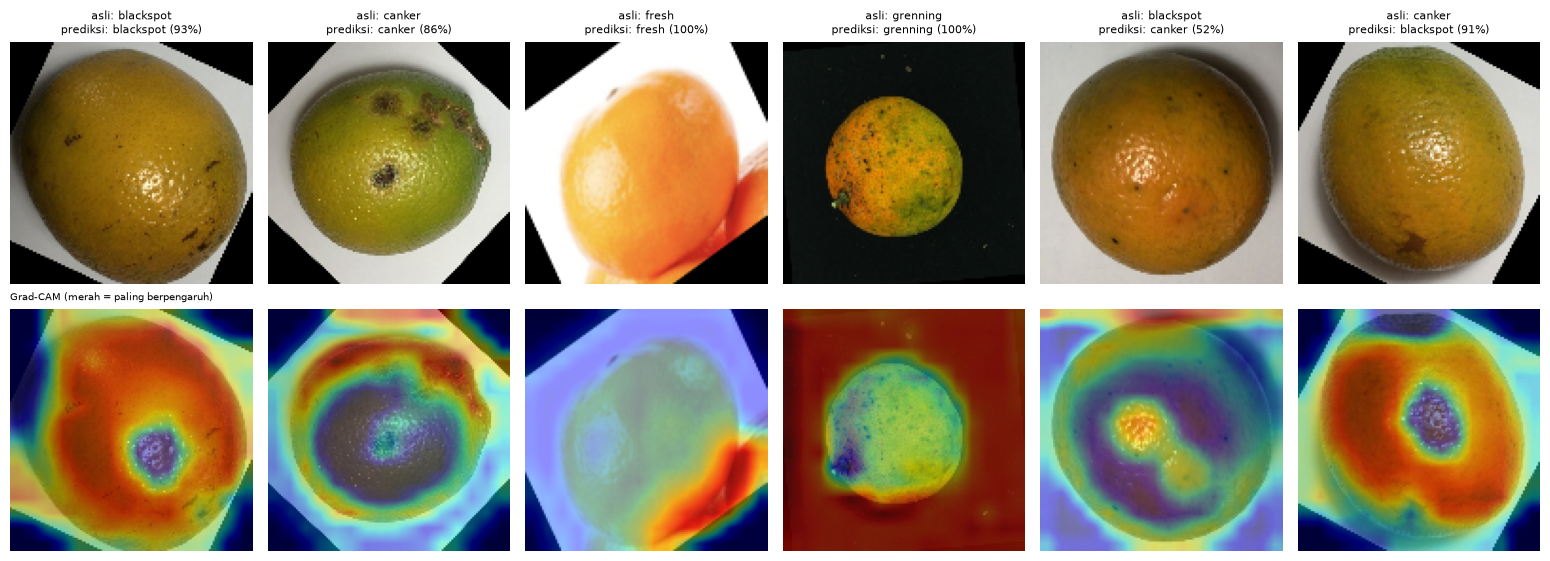

In [23]:
# contoh: satu prediksi benar per kelas, ditambah dua pasangan kesalahan yang paling sering terjadi
from collections import Counter
def muat_norm(path):
    img, _ = load_image(path, 0)               # preprocessing yang sama dengan pipeline
    return (img / 255.0).numpy()

contoh = [int(np.where((y_test == k) & (pred_test == k))[0][0]) for k in range(len(categories))]
pasangan_salah = Counter((int(a), int(b)) for a, b in zip(y_test, pred_test) if a != b).most_common(2)
for (a, b), _ in pasangan_salah:
    contoh.append(int(np.where((y_test == a) & (pred_test == b))[0][0]))

fig, axes = plt.subplots(2, len(contoh), figsize=(2.6 * len(contoh), 5.8))
for j, i in enumerate(contoh):
    img = muat_norm(p_test[i])
    cam, _ = hitung_gradcam(img, kelas=int(pred_test[i]))
    axes[0, j].imshow(img); axes[0, j].axis("off")
    axes[0, j].set_title(f"asli: {categories[y_test[i]]}\nprediksi: {categories[pred_test[i]]} "
                         f"({proba_test[i].max() * 100:.0f}%)", fontsize=8)
    axes[1, j].imshow(img); axes[1, j].imshow(cam, cmap="jet", alpha=0.45); axes[1, j].axis("off")
axes[1, 0].set_title("Grad-CAM (merah = paling berpengaruh)", fontsize=7, loc="left")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "gradcam_contoh.png"), dpi=150)
plt.show()

### 7.2 Confidence threshold
Confidence adalah probabilitas tertinggi dari softmax. Ambang dipilih dari **data validation** (bukan test):
ambang terkecil dari daftar uji yang membuat akurasi prediksi yang diterima di data validation minimal 99%.
Data test hanya dipakai untuk melaporkan dampaknya.

In [24]:
AMBANG_UJI = [0.50, 0.60, 0.70, 0.80, 0.90, 0.95, 0.99]

def evaluasi_ambang(proba, y, ambang):
    conf, pred = proba.max(1), proba.argmax(1)
    terima = conf >= ambang
    salah  = pred != y
    n = int(terima.sum())
    return {"ambang": ambang, "diterima": n, "persen_diterima": 100 * n / len(y),
            "akurasi_diterima": 100 * float(np.mean(pred[terima] == y[terima])) if n else float("nan"),
            "salah_total": int(salah.sum()), "salah_ditolak": int((salah & ~terima).sum())}

tabel_ambang = {}
for nama, proba, y in (("validation", proba_val, y_val), ("test", proba_test, y_test)):
    tabel_ambang[nama] = [evaluasi_ambang(proba, y, t) for t in AMBANG_UJI]
    print(f"\nData {nama} ({len(y)} citra)")
    print(f"{'ambang':>7s} {'diterima':>9s} {'% diterima':>11s} {'akurasi diterima':>17s} {'salah ditolak':>14s}")
    for r in tabel_ambang[nama]:
        print(f"{r['ambang']:7.2f} {r['diterima']:9d} {r['persen_diterima']:10.1f}% {r['akurasi_diterima']:16.2f}% "
              f"{r['salah_ditolak']:6d} dari {r['salah_total']}")

# pilih ambang dari data validation
AMBANG = next((r["ambang"] for r in tabel_ambang["validation"] if r["akurasi_diterima"] >= 99.0), AMBANG_UJI[-1])
print("\nAmbang terpilih (dari validation):", AMBANG)


Data validation (159 citra)
 ambang  diterima  % diterima  akurasi diterima  salah ditolak
   0.50       159      100.0%            98.74%      0 dari 2
   0.60       156       98.1%            98.72%      0 dari 2
   0.70       152       95.6%            98.68%      0 dari 2
   0.80       145       91.2%            99.31%      1 dari 2
   0.90       135       84.9%           100.00%      2 dari 2
   0.95       119       74.8%           100.00%      2 dari 2
   0.99       111       69.8%           100.00%      2 dari 2

Data test (199 citra)
 ambang  diterima  % diterima  akurasi diterima  salah ditolak
   0.50       198       99.5%            94.95%      0 dari 10
   0.60       192       96.5%            96.35%      3 dari 10
   0.70       184       92.5%            97.28%      5 dari 10
   0.80       173       86.9%            99.42%      9 dari 10
   0.90       158       79.4%            99.37%      9 dari 10
   0.95       139       69.8%           100.00%     10 dari 10
   0.99   

In [25]:
# metrik pada prediksi yang DITERIMA di data test (baris "model final dengan fitur unik" di laporan)
conf_test = proba_test.max(1)
terima = conf_test >= AMBANG
prec, rec, f1, _ = precision_recall_fscore_support(y_test[terima], pred_test[terima],
                                                  labels=list(range(len(categories))), average="macro", zero_division=0)
acc_terima = float(np.mean(pred_test[terima] == y_test[terima]))
print(f"Ambang {AMBANG}: diterima {int(terima.sum())} dari {len(y_test)} citra test ({terima.mean() * 100:.1f}%)")
print(f"Akurasi {acc_terima * 100:.2f}% | Precision (macro) {prec * 100:.2f}% | Recall (macro) {rec * 100:.2f}% | F1 (macro) {f1 * 100:.2f}%")
print("Ditolak per kelas asli:", {categories[k]: int(((y_test == k) & ~terima).sum()) for k in range(len(categories))})
print("Kesalahan yang lolos  :", int(((pred_test != y_test) & terima).sum()), "dari", int((pred_test != y_test).sum()))

Ambang 0.8: diterima 173 dari 199 citra test (86.9%)
Akurasi 99.42% | Precision (macro) 99.00% | Recall (macro) 99.04% | F1 (macro) 99.00%
Ditolak per kelas asli: {'blackspot': 13, 'canker': 10, 'fresh': 3, 'grenning': 0}
Kesalahan yang lolos  : 1 dari 10


Uji kecil untuk citra di luar domain: 16 potongan acak dari dua foto sampel bawaan scikit-learn
(`load_sample_images`, bukan jeruk) dan 8 gambar derau acak. Model tidak punya kelas "bukan jeruk",
jadi setiap citra pasti diberi salah satu dari empat label.

In [26]:
from sklearn.datasets import load_sample_images
rng = np.random.default_rng(SEED)
potongan = []
for foto in load_sample_images().images:
    H, W = foto.shape[:2]
    for _ in range(8):
        s = int(rng.integers(min(H, W) // 3, min(H, W) // 1.5))
        y0, x0 = int(rng.integers(0, H - s)), int(rng.integers(0, W - s))
        potongan.append(foto[y0:y0 + s, x0:x0 + s])
derau = [(rng.random((IMG_SIZE, IMG_SIZE, 3)) * 255).astype(np.uint8) for _ in range(8)]

def proba_citra(arr):
    x = tf.image.resize(tf.constant(arr, dtype=tf.float32), (IMG_SIZE, IMG_SIZE)) / 255.0   # sama dengan pipeline
    return model_final(x[None], training=False).numpy()[0]

hasil_ood = {}
for nama, kumpulan in (("foto bukan jeruk", potongan), ("derau acak", derau)):
    P = np.array([proba_citra(a) for a in kumpulan])
    conf = P.max(1)
    hasil_ood[nama] = {"jumlah": len(kumpulan), "diterima": int((conf >= AMBANG).sum()),
                       "ditolak": int((conf < AMBANG).sum()),
                       "prediksi_per_kelas": {categories[k]: int((P.argmax(1) == k).sum()) for k in range(len(categories))},
                       "conf_min": float(conf.min()), "conf_median": float(np.median(conf)), "conf_maks": float(conf.max())}
    print(f"{nama}: {len(kumpulan)} citra | ditolak {hasil_ood[nama]['ditolak']} | diterima {hasil_ood[nama]['diterima']} "
          f"| prediksi {hasil_ood[nama]['prediksi_per_kelas']} | conf min/median/maks "
          f"{conf.min():.2f}/{np.median(conf):.2f}/{conf.max():.2f}")

foto bukan jeruk: 16 citra | ditolak 8 | diterima 8 | prediksi {'blackspot': 2, 'canker': 4, 'fresh': 6, 'grenning': 4} | conf min/median/maks 0.51/0.78/1.00
derau acak: 8 citra | ditolak 8 | diterima 0 | prediksi {'blackspot': 0, 'canker': 0, 'fresh': 8, 'grenning': 0} | conf min/median/maks 0.58/0.71/0.74


In [27]:
# simpan ambang ke class_names.json (dibaca app.py) dan ringkasan fitur unik ke laporan/
with open(os.path.join(ROOT, "class_names.json"), encoding="utf-8") as f:
    meta = json.load(f)
meta["confidence_threshold"] = AMBANG
with open(os.path.join(ROOT, "class_names.json"), "w", encoding="utf-8") as f:
    json.dump(meta, f, indent=2)

with open(os.path.join(OUT_DIR, "fitur_unik.json"), "w", encoding="utf-8") as f:
    json.dump({"ambang_terpilih": AMBANG, "tabel_ambang": tabel_ambang, "uji_di_luar_domain": hasil_ood,
               "test_diterima": {"jumlah": int(terima.sum()), "akurasi": acc_terima,
                                 "precision_macro": float(prec), "recall_macro": float(rec), "f1_macro": float(f1)}},
              f, indent=2)
print("Tersimpan: class_names.json (confidence_threshold =", AMBANG, "), laporan/fitur_unik.json, laporan/gradcam_contoh.png")

Tersimpan: class_names.json (confidence_threshold = 0.8 ), laporan/fitur_unik.json, laporan/gradcam_contoh.png


## 8. Ekspor model ringan untuk hosting

Hosting gratis memiliki RAM terbatas (512 MB), sedangkan TensorFlow penuh membutuhkan lebih dari itu. Sel berikut menyalin model yang sama
ke format TFLite (`model_cnn.tflite`, dengan keluaran tambahan untuk Grad-CAM) dan menyimpan bobot dua lapisan Dense terakhir
(`gradcam_bobot.npz`). Aplikasi Flask memakai berkas ini bila TensorFlow tidak terpasang. Bobotnya sama dengan `model_cnn.keras`, jadi tidak ada pelatihan ulang.

In [28]:
import json, numpy as np, tensorflow as tf
from tensorflow import keras

# model dengan tiga keluaran: probabilitas, peta fitur MaxPooling terakhir, dan keluaran Dense 128 (untuk Grad-CAM)
model_final = keras.models.load_model("model_cnn.keras")
peta_terakhir = [l for l in model_final.layers if isinstance(l, keras.layers.MaxPooling2D)][-1]
model_multi = keras.Model(model_final.inputs,
                          [model_final.output, peta_terakhir.output, model_final.layers[-2].output])

konverter = tf.lite.TFLiteConverter.from_keras_model(model_multi)
with open("model_cnn.tflite", "wb") as f:
    f.write(konverter.convert())

# bobot dua Dense terakhir, dipakai untuk menghitung Grad-CAM tanpa TensorFlow
dense_a = [l for l in model_final.layers if isinstance(l, keras.layers.Dense)]
np.savez("gradcam_bobot.npz", w1=dense_a[0].kernel.numpy(), w2=dense_a[1].kernel.numpy())
print("model_cnn.tflite dan gradcam_bobot.npz tersimpan")


INFO:tensorflow:Assets written to: C:\Users\LENOVO\AppData\Local\Temp\tmpnlr84idc\assets


INFO:tensorflow:Assets written to: C:\Users\LENOVO\AppData\Local\Temp\tmpnlr84idc\assets


Saved artifact at 'C:\Users\LENOVO\AppData\Local\Temp\tmpnlr84idc'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name='input_layer')
Output Type:
  List[TensorSpec(shape=(None, 4), dtype=tf.float32, name=None), TensorSpec(shape=(None, 16, 16, 128), dtype=tf.float32, name=None), TensorSpec(shape=(None, 128), dtype=tf.float32, name=None)]
Captures:
  1553549627600: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1553549628752: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1553549628560: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1553549628176: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1553549629328: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1553549627792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1553549628944: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1553549629136: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1553549